In [20]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt

# Load the professor's clusters and my k=3 clusters.
professor = pd.read_csv('clusters3.csv')
mine = pd.read_csv('clusters3_redo.csv')

# Rename columns consistently. The first professor column contains fighter names.
professor = professor.rename(columns={
    professor.columns[0]: 'fighter',
    professor.columns[1]: 'professor_cluster'
})
mine = mine[['fighter', 'cluster']].rename(columns={'cluster': 'my_cluster'})

# Compare only fighters present in both datasets.
comparison = professor.merge(mine, on='fighter', how='inner', validate='one_to_one')
comparison['professor_cluster'] = comparison['professor_cluster'].astype(int)
comparison['my_cluster'] = comparison['my_cluster'].astype(int)

# Cluster numbers are arbitrary. Test every possible one-to-one mapping
# between the professor's labels and my labels, then keep the best mapping.
professor_labels = sorted(comparison['professor_cluster'].unique())
my_labels = sorted(comparison['my_cluster'].unique())

best_mapping = None
best_same_count = -1

for professor_permutation in itertools.permutations(professor_labels):
    mapping = dict(zip(my_labels, professor_permutation))
    aligned_my_clusters = comparison['my_cluster'].map(mapping)
    same_count = (aligned_my_clusters == comparison['professor_cluster']).sum()

    if same_count > best_same_count:
        best_same_count = same_count
        best_mapping = mapping

comparison['my_cluster_aligned'] = comparison['my_cluster'].map(best_mapping)
same_cluster = comparison['professor_cluster'] == comparison['my_cluster_aligned']
percentage_same = same_cluster.mean() * 100
percentage_different = 100 - percentage_same

results = pd.Series({
    'Same cluster': percentage_same,
    'Different cluster': percentage_different
})

print(f'Fighters compared: {len(comparison)}')
print(f'Best mapping from my labels to professor labels: {best_mapping}')
results

Fighters compared: 2683
Best mapping from my labels to professor labels: {np.int64(1): np.int64(1), np.int64(2): np.int64(2), np.int64(3): np.int64(3)}


Same cluster         99.515468
Different cluster     0.484532
dtype: float64

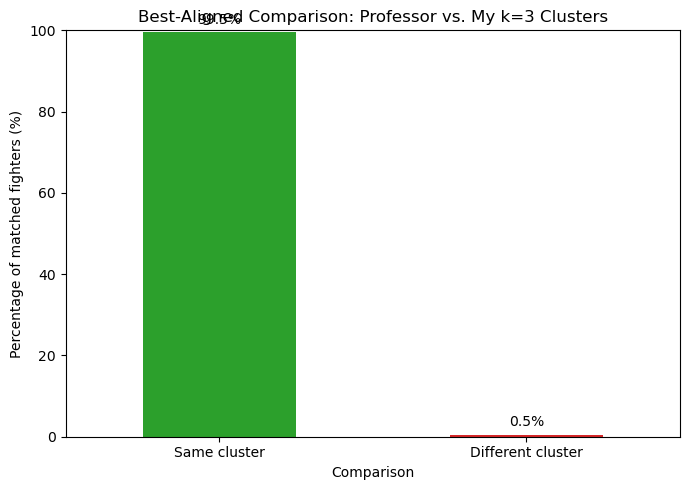

In [21]:
# One visual: best-aligned percentage of fighters in the same vs. different cluster.
ax = results.plot(
    kind='bar',
    color=['#2ca02c', '#d62728'],
    figsize=(7, 5),
    ylim=(0, 100),
    title='Best-Aligned Comparison: Professor vs. My k=3 Clusters'
)

ax.set_xlabel('Comparison')
ax.set_ylabel('Percentage of matched fighters (%)')
ax.set_xticklabels(['Same cluster', 'Different cluster'], rotation=0)

for bar, value in zip(ax.patches, results):
    ax.annotate(
        f'{value:.1f}%',
        (bar.get_x() + bar.get_width() / 2, value),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()